# Libraries

In [8]:
from datasets import load_dataset, concatenate_datasets
from rank_bm25 import BM25Okapi
import pandas as pd
import numpy as np

# Load Dataset

###  SweFaqRetrieval

In [9]:
swefaq_corpus = load_dataset("mteb/SweFaqRetrieval", "corpus")["test"]
swefaq_queries = load_dataset("mteb/SweFaqRetrieval", "queries")["test"]
swefaq_qrels = load_dataset("mteb/SweFaqRetrieval", "qrels")["test"]

### SwednRetrieval

In [10]:
splits = ["train", "validation", "test"]
all_corpus, all_queries, all_qrels = [], [], []

for split in splits:
    corpus_split = load_dataset("mteb/SwednRetrieval", "corpus")[split].map(lambda x: {"_id": f"{split}_{x['_id']}"})
    queries_split = load_dataset("mteb/SwednRetrieval", "queries")[split].map(lambda x: {"_id": f"{split}_{x['_id']}"})
    qrels_split = load_dataset("mteb/SwednRetrieval", "qrels")[split].map(lambda x: {
        "query-id": f"{split}_{x['query-id']}",
        "corpus-id": f"{split}_{x['corpus-id']}"
    })
    all_corpus.append(corpus_split)
    all_queries.append(queries_split)
    all_qrels.append(qrels_split)

swedn_corpus = concatenate_datasets(all_corpus)
swedn_queries = concatenate_datasets(all_queries)
swedn_qrels = concatenate_datasets(all_qrels)

Map:   0%|          | 0/2048 [00:00<?, ? examples/s]

Map:   0%|          | 0/1024 [00:00<?, ? examples/s]

Map:   0%|          | 0/2048 [00:00<?, ? examples/s]

Map:   0%|          | 0/2047 [00:00<?, ? examples/s]

Map:   0%|          | 0/1024 [00:00<?, ? examples/s]

Map:   0%|          | 0/2048 [00:00<?, ? examples/s]

Map:   0%|          | 0/2046 [00:00<?, ? examples/s]

Map:   0%|          | 0/1024 [00:00<?, ? examples/s]

Map:   0%|          | 0/2048 [00:00<?, ? examples/s]

# Evaluation
Build `qrels dictionary` for lookup qrels. This creates a set of relevant document IDs for each query ID. We use it during evaluation to check whether the retrieval system finds the correct documents.

In [11]:
def build_qrels_dict(qrels):
    qrels_dict = {}
    for row in qrels:
        qid = row["query-id"]
        did = row["corpus-id"]
        qrels_dict.setdefault(qid, set()).add(did)
    return qrels_dict

swefaq_qrels_dict = build_qrels_dict(swefaq_qrels)
swedn_qrels_dict = build_qrels_dict(swedn_qrels)

### BM25 function
BM25 is a sparse retrieval method that ranks documents based on their relevance to a query. It considers term frequency, inverse document frequency (IDF), and document length.

**Implementation:**
1. Extract document IDs and text from the corpus.
2. Convert the text into lowercase tokens using `.lower().split()`.
3. Build the BM25 index using `BM25Okapi`.
4. Calculate relevance scores for documents matching a query.
5. Rank documents by score, from highest to lowest.

**BM25 formula:**
$$
\operatorname{BM25}(q,d)
=
\sum_{t \in q}
\operatorname{IDF}(t)
\frac{f(t,d)(k_1+1)}
{f(t,d)+k_1\left(1-b+b\frac{|d|}{\operatorname{avgdl}}\right)}
$$

Here, $f(t,d)$ is the frequency of a query term in a document, $|d|$ is document length, and $\operatorname{avgdl}$ is the average document length. The parameters $k_1$ and $b$ control term-frequency saturation and document-length normalization.

We use BM25 as our baseline to compare its performance with dense and hybrid retrieval methods.

In [12]:
def build_bm25(corpus):
    corpus_ids = [doc["_id"] for doc in corpus]
    corpus_texts = [doc["text"] for doc in corpus]
    tokenized_corpus = [text.lower().split() for text in corpus_texts]
    bm25 = BM25Okapi(tokenized_corpus)
    return bm25, corpus_ids, corpus_texts

swefaq_bm25, swefaq_corpus_ids, swefaq_corpus_texts = build_bm25(swefaq_corpus)
swedn_bm25, swedn_corpus_ids, swedn_corpus_texts = build_bm25(swedn_corpus)

### Recall@k and nDCG
We evaluate BM25 using Recall@1, Recall@3, Recall@10, and nDCG@10.

#### Recall@k
Recall@k measures the proportion of relevant documents retrieved in the top k results.

$$
\operatorname{Recall@k}(q)=
\frac{|R_q \cap T_k(q)|}{|R_q|}
$$

Here, $R_q$ is the set of relevant documents from qrels, and $T_k(q)$ is the set of top-k retrieved documents. For example, if 2 out of 4 relevant documents appear in the top 3, $Recall@3 = 0.5$.

#### nDCG@10

$nDCG@10$ measures whether relevant documents appear near the top of the ranking. Our implementation uses binary relevance: relevant documents receive 1, and non-relevant documents receive 0.

$$
\operatorname{DCG@k}=
\sum_{i=1}^{k}\frac{rel_i}{\log_2(i+1)}
$$

$$
\operatorname{nDCG@k}=
\frac{\operatorname{DCG@k}}{\operatorname{IDCG@k}}
$$

IDCG represents the ideal ranking score. nDCG ranges from 0 to 1, with 1 indicating an ideal ranking.

We calculate these metrics for each query and average the scores to compare BM25 performance on SweFAQ and SwednRetrieval.


In [13]:
def recall_at_k(retrieved_ids, relevant_ids, k):
    top_k = set(retrieved_ids[:k])
    if len(relevant_ids) == 0:
        return None
    return len(top_k & relevant_ids) / len(relevant_ids)

def ndcg_at_k(retrieved_ids, relevant_ids, k):
    dcg = 0.0
    for i, doc_id in enumerate(retrieved_ids[:k]):
        if doc_id in relevant_ids:
            dcg += 1 / np.log2(i + 2)
    ideal_hits = min(len(relevant_ids), k)
    idcg = sum(1 / np.log2(i + 2) for i in range(ideal_hits))
    if idcg == 0:
        return None
    return dcg / idcg

### Evaluation Function
This function evaluates BM25 on each query using Recall@1, Recall@3, Recall@10, and nDCG@10.

For each query, it calculates BM25 scores for all documents, selects the top 10 documents, and compares them with the relevant document IDs from the qrels. It then calculates the evaluation metrics and averages the scores across queries to get the final results for each dataset.

In [14]:
def evaluate_bm25(bm25, corpus_ids, queries, qrels_dict, k_values=[1, 3, 10]):
    results = {f"Recall@{k}": [] for k in k_values}
    results["nDCG@10"] = []

    for q in queries:
        qid = q["_id"]
        if qid not in qrels_dict:
            continue
        query_text = q["text"]
        tokenized_query = query_text.lower().split()
        scores = bm25.get_scores(tokenized_query)
        top_indices = scores.argsort()[::-1][:10]
        retrieved_ids = [corpus_ids[i] for i in top_indices]

        relevant_ids = qrels_dict[qid]

        for k in k_values:
            r = recall_at_k(retrieved_ids, relevant_ids, k)
            if r is not None:
                results[f"Recall@{k}"].append(r)

        ndcg = ndcg_at_k(retrieved_ids, relevant_ids, 10)
        if ndcg is not None:
            results["nDCG@10"].append(ndcg)

    summary = {metric: np.mean(vals) for metric, vals in results.items()}
    return summary

In [15]:
swefaq_results = evaluate_bm25(swefaq_bm25, swefaq_corpus_ids, swefaq_queries, swefaq_qrels_dict)
swedn_results = evaluate_bm25(swedn_bm25, swedn_corpus_ids, swedn_queries, swedn_qrels_dict)

print("SweFAQ BM25 results:", swefaq_results)
print("SwednRetrieval BM25 results:", swedn_results)

SweFAQ BM25 results: {'Recall@1': np.float64(0.23196881091617932), 'Recall@3': np.float64(0.39571150097465885), 'Recall@10': np.float64(0.5886939571150097), 'nDCG@10': np.float64(0.39565532026403527)}
SwednRetrieval BM25 results: {'Recall@1': np.float64(0.2978515625), 'Recall@3': np.float64(0.5123697916666666), 'Recall@10': np.float64(0.6149088541666666), 'nDCG@10': np.float64(0.5708603348539056)}


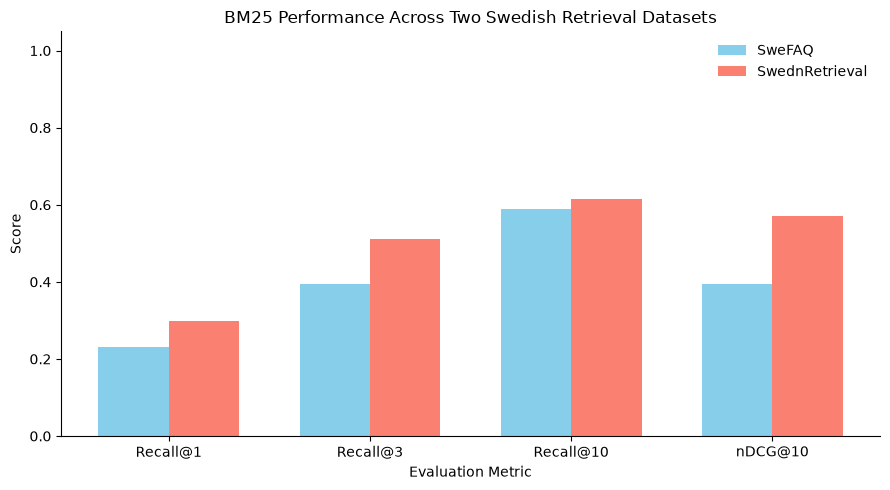

In [31]:
import matplotlib.pyplot as plt
import numpy as np

# Metrics to compare
metrics = ["Recall@1", "Recall@3", "Recall@10", "nDCG@10"]

# Get scores from the results table
plot_data = results_table.set_index("Dataset")[metrics]

# Create grouped bar chart
fig, ax = plt.subplots(figsize=(9, 5))

x = np.arange(len(metrics))
width = 0.35

ax.bar(
    x - width / 2,
    plot_data.loc["SweFAQ"],
    width,
    color='skyblue',
    label="SweFAQ"
)

ax.bar(
    x + width / 2,
    plot_data.loc["SwednRetrieval"],
    width,
    color='salmon',
    label="SwednRetrieval"
)

# Labels and formatting
ax.set_xlabel("Evaluation Metric")
ax.set_ylabel("Score")
ax.set_title("BM25 Performance Across Two Swedish Retrieval Datasets")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.05)

ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(frameon=False)

plt.tight_layout()
plt.show()

#### Save to CSV

In [16]:
results_table = pd.DataFrame([
    {"Dataset": "SweFAQ", "Method": "BM25", **swefaq_results},
    {"Dataset": "SwednRetrieval", "Method": "BM25", **swedn_results},
])
results_table.to_csv("../results/bm25_results.csv", index=False)
print(results_table)

          Dataset Method  Recall@1  Recall@3  Recall@10   nDCG@10
0          SweFAQ   BM25  0.231969  0.395712   0.588694  0.395655
1  SwednRetrieval   BM25  0.297852  0.512370   0.614909  0.570860


# Example

In [20]:
def show_example(corpus, queries, qrels_dict, bm25, corpus_ids, corpus_texts, query_idx=0, k=10):
    q = queries[query_idx]
    qid = q["_id"]
    query_text = q["text"]

    tokenized_query = query_text.lower().split()
    scores = bm25.get_scores(tokenized_query)
    top_indices = scores.argsort()[::-1][:k]

    relevant_ids = qrels_dict.get(qid, set())

    print("QUERY:", query_text)
    print("RELEVANT (gold) IDs:", relevant_ids)
    print()
    print(f"TOP-{k} RETRIEVED:")
    for rank, idx in enumerate(top_indices, start=1):
        doc_id = corpus_ids[idx]
        is_correct = "CORRECT" if doc_id in relevant_ids else ""
        print(f"{rank}. id={doc_id} score={scores[idx]:.2f} {is_correct}")
        print(f"   {corpus_texts[idx][:150]}")
    print("-"*80)

In [21]:
# sweFAQ example
show_example(swefaq_corpus, swefaq_queries, swefaq_qrels_dict, swefaq_bm25, swefaq_corpus_ids, swefaq_corpus_texts, query_idx=0)

QUERY: Får jag lägre föräldrapenning om jag går ner i arbetstid innan förlossningen?
RELEVANT (gold) IDs: {'2'}

TOP-10 RETRIEVED:
1. id=147 score=17.66 
   Ja, du har rätt att förkorta din arbetstid med upp till 25 procent om du eller en annan förälder får vårdbidrag för barnet. Det gäller även efter att 
2. id=2 score=15.81 CORRECT
   Nej, inte om det är 6 månader eller kortare tid kvar till den planerade förlossningen. Din föräldrapenning beräknas på den inkomst du hade innan du gi
3. id=619 score=14.80 
   Det är din region som ansvarar för vaccinationerna. I texten När och hur kan jag vaccinera mig mot covid-19 kan du läsa mer om vilka som erbjuds vacci
4. id=544 score=12.74 
   Du kan ha rätt till ersättning om du har deltagit eller har haft frånvaro som kan ge rätt till ersättning under dessa dagar. Det är Arbetsförmedlingen
5. id=59 score=11.31 
   Om du har varit ledig en månad eller längre har arbetsgivaren rätt att låta dig vänta i högst en månad innan du får börja jobba ige

In [23]:
# SwednRetrieval example
show_example(swedn_corpus, swedn_queries, swedn_qrels_dict, swedn_bm25, swedn_corpus_ids, swedn_corpus_texts, query_idx=0)

QUERY: Många unga skadas på cykel och moped
RELEVANT (gold) IDs: {'train_2', 'train_1'}

TOP-10 RETRIEVED:
1. id=validation_2776 score=20.79 
   I Mark Knopflers musikstudio i västra London står en moped parkerad bredvid en Porsche (som senare visar sig tillhöra musikkollegan Eric Clapton). Kno
2. id=test_1499 score=19.11 
   resebilagan@dn.se 08-738 11 99 Tåg- eller cykelsemester? Sveriges hårt prövade cyklister får i sommar chansen att svara "bådadera". Under två månader,
3. id=train_1475 score=17.31 
   Två gånger har Mora slagit kritikerna på fingrarna. Under NHL-lockouten räddades elitserieplatsen tämligen enkelt och i fjol gick man till slutspel dä
4. id=test_2463 score=17.18 
   Av diskussionen är det lätt att tro att cyklister är en homogen grupp – bara för att du sätter dig på cykeln blir du en person som färdas mer aggressi
5. id=train_1142 score=17.17 
   Skjutningen i München började inne på en McDonalds-restaurang och fortsatt därefter inne i ett köpcenter vid Olympia Eink

# Error Analysis

#### Which three queries failed to retrieve relevant documents?

In [26]:
def find_failed_queries(queries, qrels_dict, bm25, corpus_ids, n=3):
    failed = []
    for q in queries:
        qid = q["_id"]
        if qid not in qrels_dict:
            continue
        tokenized_query = q["text"].lower().split()
        scores = bm25.get_scores(tokenized_query)
        top_indices = scores.argsort()[::-1][:10]
        retrieved_ids = set(corpus_ids[i] for i in top_indices)
        relevant_ids = qrels_dict[qid]

        if len(retrieved_ids & relevant_ids) == 0:  # Recall@10 = 0, miss
            failed.append(q)
        if len(failed) >= n:
            break
    return failed

In [27]:
failed_swefaq = find_failed_queries(swefaq_queries, swefaq_qrels_dict, swefaq_bm25, swefaq_corpus_ids, n=3)
for q in failed_swefaq:
    print(q["text"])

Kan jag som är den andra föräldern vara föräldraledig innan jag står som vårdnadshavare till barnet?
Får jag pengar för lördagar och söndagar?
Kan jag ansöka på webben om jag har skyddad identitet?


### BM25 Failure Analysis — Initial Observations 
##### SweFAQ
Manually inspected 3 queries where BM25 retrieved no relevant document in top-10:
1. **Complex/conditional query**: BM25 matches topically-related terms but cannot capture
   the specific logical condition in the question (e.g. "before becoming legal guardian").
2. **Generic/short query**: Query lacks domain-specific keywords, matching many
   topically-unrelated documents that happen to share common words ("pengar", "söndagar").
3. **Lexical mismatch (synonymy)**: Query uses a different word ("webben") than the
   answer document ("Mina sidor") for the same concept — BM25 cannot bridge this gap.

These failure modes motivate the dense retrieval comparison (RQ1) — cases 2 and 3 in
particular are classic situations where semantic embedding models are expected to
outperform lexical matching.

In [29]:
failed_swedn = find_failed_queries(swedn_queries, swedn_qrels_dict, swedn_bm25, swedn_corpus_ids, n=3)
for q in failed_swedn:
    print(q["text"])

Nylander hetaste svensken i draften
"Backe till Rosenborg"
Ekonom: Avtalet innebär rundgång


#### SwednRetrieval

Manually inspected failure-case queries:

1. "Nylander hetaste svensken i draften" — headline uses editorializing language
   ("hetaste" = hottest) likely absent from the factual article body.
2. "Backe till Rosenborg" — minimal telegraphic headline (no verb); relies on
   proper-noun matching, which may favor BM25.
3. "Ekonom: Avtalet innebär rundgång" — headline contains a compound word
   ("rundgång") that may not appear verbatim in the article body, directly
   relevant to RQ2 (compound-word density).

Unlike SweFAQ, where failures stemmed from lexical synonymy between query and
answer (e.g. "webben" vs "Mina sidor"), SwednRetrieval failures appear to stem
from a structural mismatch between compressed, editorializing headline language
and descriptive article body text — a distinct domain effect relevant to RQ3.